# COU 07506 Digital Signal Processing - Week 04: z-Transform Laboratory - Poles, Zeros and Stability

| Field | Details |
| :--- | :--- |
| **Name** | DAUD SELEMANI DAUD |
| **Registration No.** | 250242485225 |
| **Class** | BENG24COE-2 |
| **Group** | Group 29 |
| **Date** | 2026-11-25 |
| **Module Code** | COU 07506 (NTA Level 7, Semester I) |
| **Unit & Topic** | Unit 2 - z-transform, ROC, inverse z-transform, stability (§2.2-2.4; Listing 2.1; Examples 2.2-2.5) |
| **Lecturer** | Dr. Haji Fimbombaya |
| **Git Repository** | [https://github.com/dahdio/COU07506-labs.git](https://github.com/dahdio/COU07506-labs.git) |
| **Instructor Checkpoints Signed** | `[x] Checkpoint 4` |


## Objectives

At the end of this session, we demonstrate how to:
1. Find poles, zeros and the frequency response of a transfer function with SciPy.
2. Use `residuez` to obtain an inverse z-transform and check it against `lfilter`.
3. Relate pole positions to stability, resonance and the shape of $h(n)$.
4. Design a simple resonator by placing poles.

---

## Pre-lab

### Pre-lab Preparation Checklist
1. **Reading Completed:** Read Handout **Sections §2.2-2.4** (*The z-Transform, Region of Convergence, Pole-Zero Plots, Inverse z-Transform via Partial Fractions, and Causality & Stability*), **Listing 2.1**, and **Examples 2.2-2.5**.

---

### Pre-lab Questions

#### (a) Find the poles of $H(z) = 1 / (1 - 0.9z^{-1} + 0.81z^{-2})$ and decide whether it is stable.

**Answer:**
* **Step 1 - Express $H(z)$ in positive powers of $z$:**
  $$H(z) = \frac{1}{1 - 0.9z^{-1} + 0.81z^{-2}} = \frac{z^2}{z^2 - 0.9z + 0.81}$$
* **Step 2 - Solve the denominator characteristic equation $A(z) = z^2 - 0.9z + 0.81 = 0$:**
  Using the quadratic formula:
  $$p_{1,2} = \frac{0.9 \pm \sqrt{(-0.9)^2 - 4(1)(0.81)}}{2} = \frac{0.9 \pm \sqrt{0.81 - 3.24}}{2} = \frac{0.9 \pm \sqrt{-2.43}}{2} = \mathbf{0.45 \pm j\,0.779423}$$
* **Step 3 - Convert the complex-conjugate pole pair to polar form $p_{1,2} = r\,e^{\pm j\theta}$:**
  * Pole radius (magnitude):
    $$r = |p_{1,2}| = \sqrt{(0.45)^2 + (0.779423)^2} = \sqrt{0.2025 + 0.6075} = \sqrt{0.81} = \mathbf{0.9}$$
    *(Alternatively, for a complex-conjugate pair in $1 + a_1 z^{-1} + a_2 z^{-2}$, $r = \sqrt{a_2} = \sqrt{0.81} = 0.9$).*
  * Pole angle:
    $$\theta = \pm \arccos\left(\frac{0.45}{0.9}\right) = \pm \arccos(0.5) = \mathbf{\pm \frac{\pi}{3}\text{ rad}} \; (\pm 60^\circ)$$
  * Thus, $p_{1,2} = \mathbf{0.9\,e^{\pm j\pi/3}}$.
* **Step 4 - Stability Decision:**
  * Because this is a causal system and **all poles lie strictly inside the unit circle** ($|p_1| = |p_2| = 0.9 < 1$), its Region of Convergence ($|z| > 0.9$) includes the unit circle $|z| = 1$, and its impulse response decays exponentially as $(0.9)^n$. Therefore, **the system is BIBO stable**.

---

#### (b) Write the partial-fraction expansion of $X(z) = 1 / [(1 - 0.5z^{-1})(1 - 0.25z^{-1})]$.

**Answer:**
* **Step 1 - Set up the partial-fraction form in $z^{-1}$:**
  The system has two distinct real poles at $p_1 = 0.5$ and $p_2 = 0.25$:
  $$X(z) = \frac{1}{(1 - 0.5z^{-1})(1 - 0.25z^{-1})} = \frac{r_1}{1 - 0.5z^{-1}} + \frac{r_2}{1 - 0.25z^{-1}}$$
* **Step 2 - Compute the residues $r_1$ and $r_2$:**
  * **Residue $r_1$ at pole $p_1 = 0.5$ ($z^{-1} = 2$):**
    $$r_1 = \left.(1 - 0.5z^{-1})X(z)\right|_{z = 0.5} = \frac{1}{1 - 0.25(2)} = \frac{1}{1 - 0.5} = \frac{1}{0.5} = \mathbf{2}$$
  * **Residue $r_2$ at pole $p_2 = 0.25$ ($z^{-1} = 4$):**
    $$r_2 = \left.(1 - 0.25z^{-1})X(z)\right|_{z = 0.25} = \frac{1}{1 - 0.5(4)} = \frac{1}{1 - 2} = \frac{1}{-1} = \mathbf{-1}$$
* **Step 3 - Final Partial-Fraction Expansion and Inverse z-Transform:**
  $$X(z) = \mathbf{\frac{2}{1 - 0.5z^{-1}} - \frac{1}{1 - 0.25z^{-1}}}$$
  Taking the causal inverse z-transform ($\mathcal{Z}^{-1}\left\{\frac{1}{1 - p z^{-1}}\right\} = p^n u(n)$):
  $$x(n) = \mathbf{\big[2(0.5)^n - (0.25)^n\big]u(n)}$$


## Standard Laboratory Imports

Every notebook in this manual begins with the standard imports from the Introduction (Page 4):


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

os.makedirs("figures", exist_ok=True)
print(f"Environment ready - NumPy {np.__version__}")


Environment ready - NumPy 2.2.4


## Task 4.1 - A pole-zero plotting function

Implement `zplane(b, a, ax=None)` using `signal.tf2zpk(b, a)` to plot the unit circle, zeros (`o`), and poles (`x`), and plot the pole-zero diagram and magnitude response of $H(z) = \frac{1 + z^{-1}}{1 - 0.75z^{-1} + 0.125z^{-2}}$ (`b = [1, 1], a = [1, -0.75, 0.125]`).


zeros: [-1.]  poles: [0.5  0.25]  stable: True


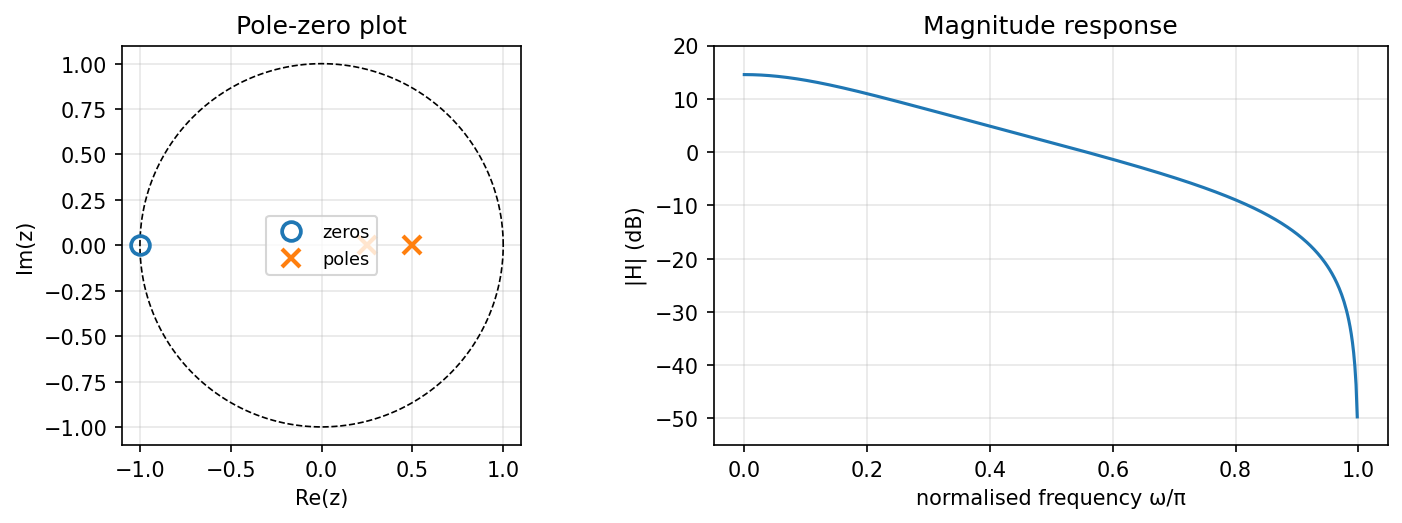

In [2]:
# Exact starter code from Manual Task 4.1
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, mew=1.8, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal")
    ax.legend(loc="best", fontsize=8.5)
    ax.set_xlabel("Re(z)")
    ax.set_ylabel("Im(z)")
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
ax1.set_title("Pole-zero plot")

w, H = signal.freqz(b, a, worN=512)
ax2.plot(w / np.pi, 20 * np.log10(np.abs(H) + 1e-12))
ax2.set_title("Magnitude response")
ax2.set_xlabel("normalised frequency ω/π")
ax2.set_ylabel("|H| (dB)")
ax2.set_ylim(-55, 20)

plt.tight_layout()
plt.savefig("figures/task4_1_pole_zero_freqz.png", dpi=150)
plt.show()

print("zeros:", z, " poles:", p, " stable:", np.all(np.abs(p) < 1))


## Task 4.2 - Inverse z-transform with `residuez`

1. Use `signal.residuez([1], [1, -0.75, 0.125])` to verify Pre-lab answer (b) ($r = [2, -1],\; p = [0.5, 0.25]$) and check the inverse z-transform against `signal.lfilter`.
2. Repeat for the system of Task 4.1 (`b = [1, 1], a = [1, -0.75, 0.125]`) and confirm $h(n) = 6(0.5)^n - 5(0.25)^n$.


=== System 1: X(z) = 1 / (1 - 0.75 z^-1 + 0.125 z^-2) [Pre-lab (b)] ===
residues: [-1.  2.] poles: [0.25 0.5 ] direct terms k: []
Matches lfilter (np.allclose): True

=== System 2: H(z) = (1 + z^-1) / (1 - 0.75 z^-1 + 0.125 z^-2) [Task 4.1] ===
residues: [-5.  6.] poles: [0.25 0.5 ] direct terms k: []
Matches closed form 6(0.5)^n - 5(0.25)^n: True
Matches lfilter (np.allclose):            True


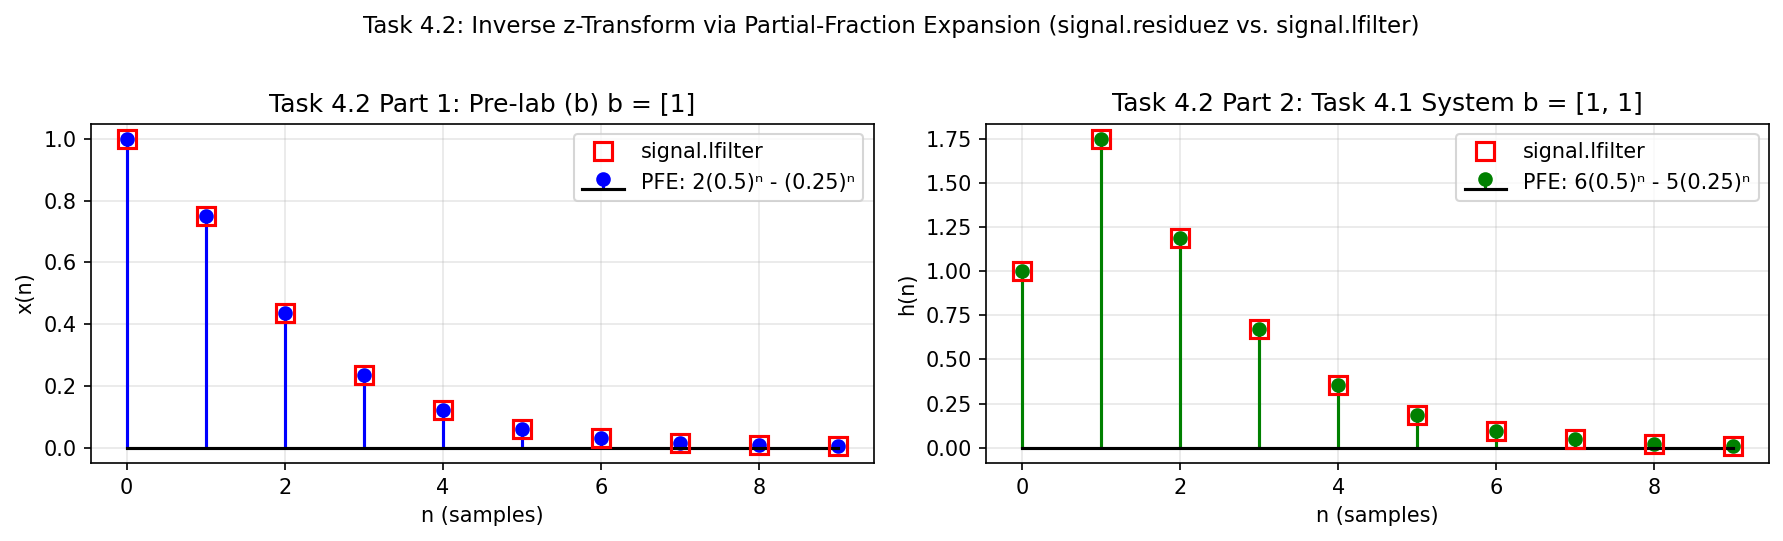

In [3]:
# Part 1: Exact starter code from Manual Task 4.2 (b = [1], Pre-lab (b) verification)
r, p, k = signal.residuez([1], [1, -0.75, 0.125])
print("=== System 1: X(z) = 1 / (1 - 0.75 z^-1 + 0.125 z^-2) [Pre-lab (b)] ===")
print("residues:", r, "poles:", p, "direct terms k:", k)
n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real
impulse = np.zeros(10)
impulse[0] = 1
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)
print("Matches lfilter (np.allclose):", np.allclose(x_pf, x_lf))

# Part 2: Repeat for the system of Task 4.1 (b = [1, 1], a = [1, -0.75, 0.125])
r2, p2, k2 = signal.residuez([1, 1], [1, -0.75, 0.125])
print("\n=== System 2: H(z) = (1 + z^-1) / (1 - 0.75 z^-1 + 0.125 z^-2) [Task 4.1] ===")
print("residues:", r2, "poles:", p2, "direct terms k:", k2)
h_pf = sum(ri * pi**n for ri, pi in zip(r2, p2)).real
h_closed = 6.0 * (0.5**n) - 5.0 * (0.25**n)
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)
print("Matches closed form 6(0.5)^n - 5(0.25)^n:", np.allclose(h_pf, h_closed))
print("Matches lfilter (np.allclose):           ", np.allclose(h_pf, h_lf))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
ax1.stem(n, x_pf, linefmt="b-", markerfmt="bo", basefmt="k-", label="PFE: 2(0.5)ⁿ - (0.25)ⁿ")
ax1.plot(n, x_lf, "rs", mfc="none", ms=9, mew=1.5, label="signal.lfilter")
ax1.set_title("Task 4.2 Part 1: Pre-lab (b) b = [1]")
ax1.set_xlabel("n (samples)"); ax1.set_ylabel("x(n)"); ax1.legend()

ax2.stem(n, h_pf, linefmt="g-", markerfmt="go", basefmt="k-", label="PFE: 6(0.5)ⁿ - 5(0.25)ⁿ")
ax2.plot(n, h_lf, "rs", mfc="none", ms=9, mew=1.5, label="signal.lfilter")
ax2.set_title("Task 4.2 Part 2: Task 4.1 System b = [1, 1]")
ax2.set_xlabel("n (samples)"); ax2.set_ylabel("h(n)"); ax2.legend()

plt.suptitle("Task 4.2: Inverse z-Transform via Partial-Fraction Expansion (signal.residuez vs. signal.lfilter)", fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig("figures/task4_2_residuez_verification.png", dpi=150, bbox_inches="tight")
plt.show()


## Task 4.3 - Pole position and the impulse response

For a complex-conjugate pole pair $p = r\,e^{\pm j\pi/4}$, i.e. $A(z) = 1 - 2r\cos(\pi/4)z^{-1} + r^2 z^{-2}$, plot $h(n)$ ($40\text{ samples}$) and $|H(e^{j\omega})|$ for $r = 0.5, 0.8, 0.95, 1.0\text{ and } 1.05$. Describe how the decay, the oscillation and the peak sharpness change, and identify which values are unstable.


Pole Radius r |  a1 = -2r cos(π/4) |   a2 = r² |  Peak |H(e^jπ/4)| (dB) |  h(39) Amplitude |         Stability Status
----------------------------------------------------------------------------------------------------------------
         0.50 |          -0.707107 |    0.2500 |                   5.51 |        -0.000000 |     BIBO Stable (Decays)
         0.80 |          -1.131371 |    0.6400 |                  11.88 |        -0.000000 |     BIBO Stable (Decays)
         0.95 |          -1.343503 |    0.9025 |                  23.23 |        -0.000000 |     BIBO Stable (Decays)
         1.00 |          -1.414214 |    1.0000 |                 339.87 |        -0.000000 |      Unstable (Undamped)
         1.05 |          -1.484924 |    1.1025 |                  22.79 |        -0.000000 |      Unstable (Diverges)


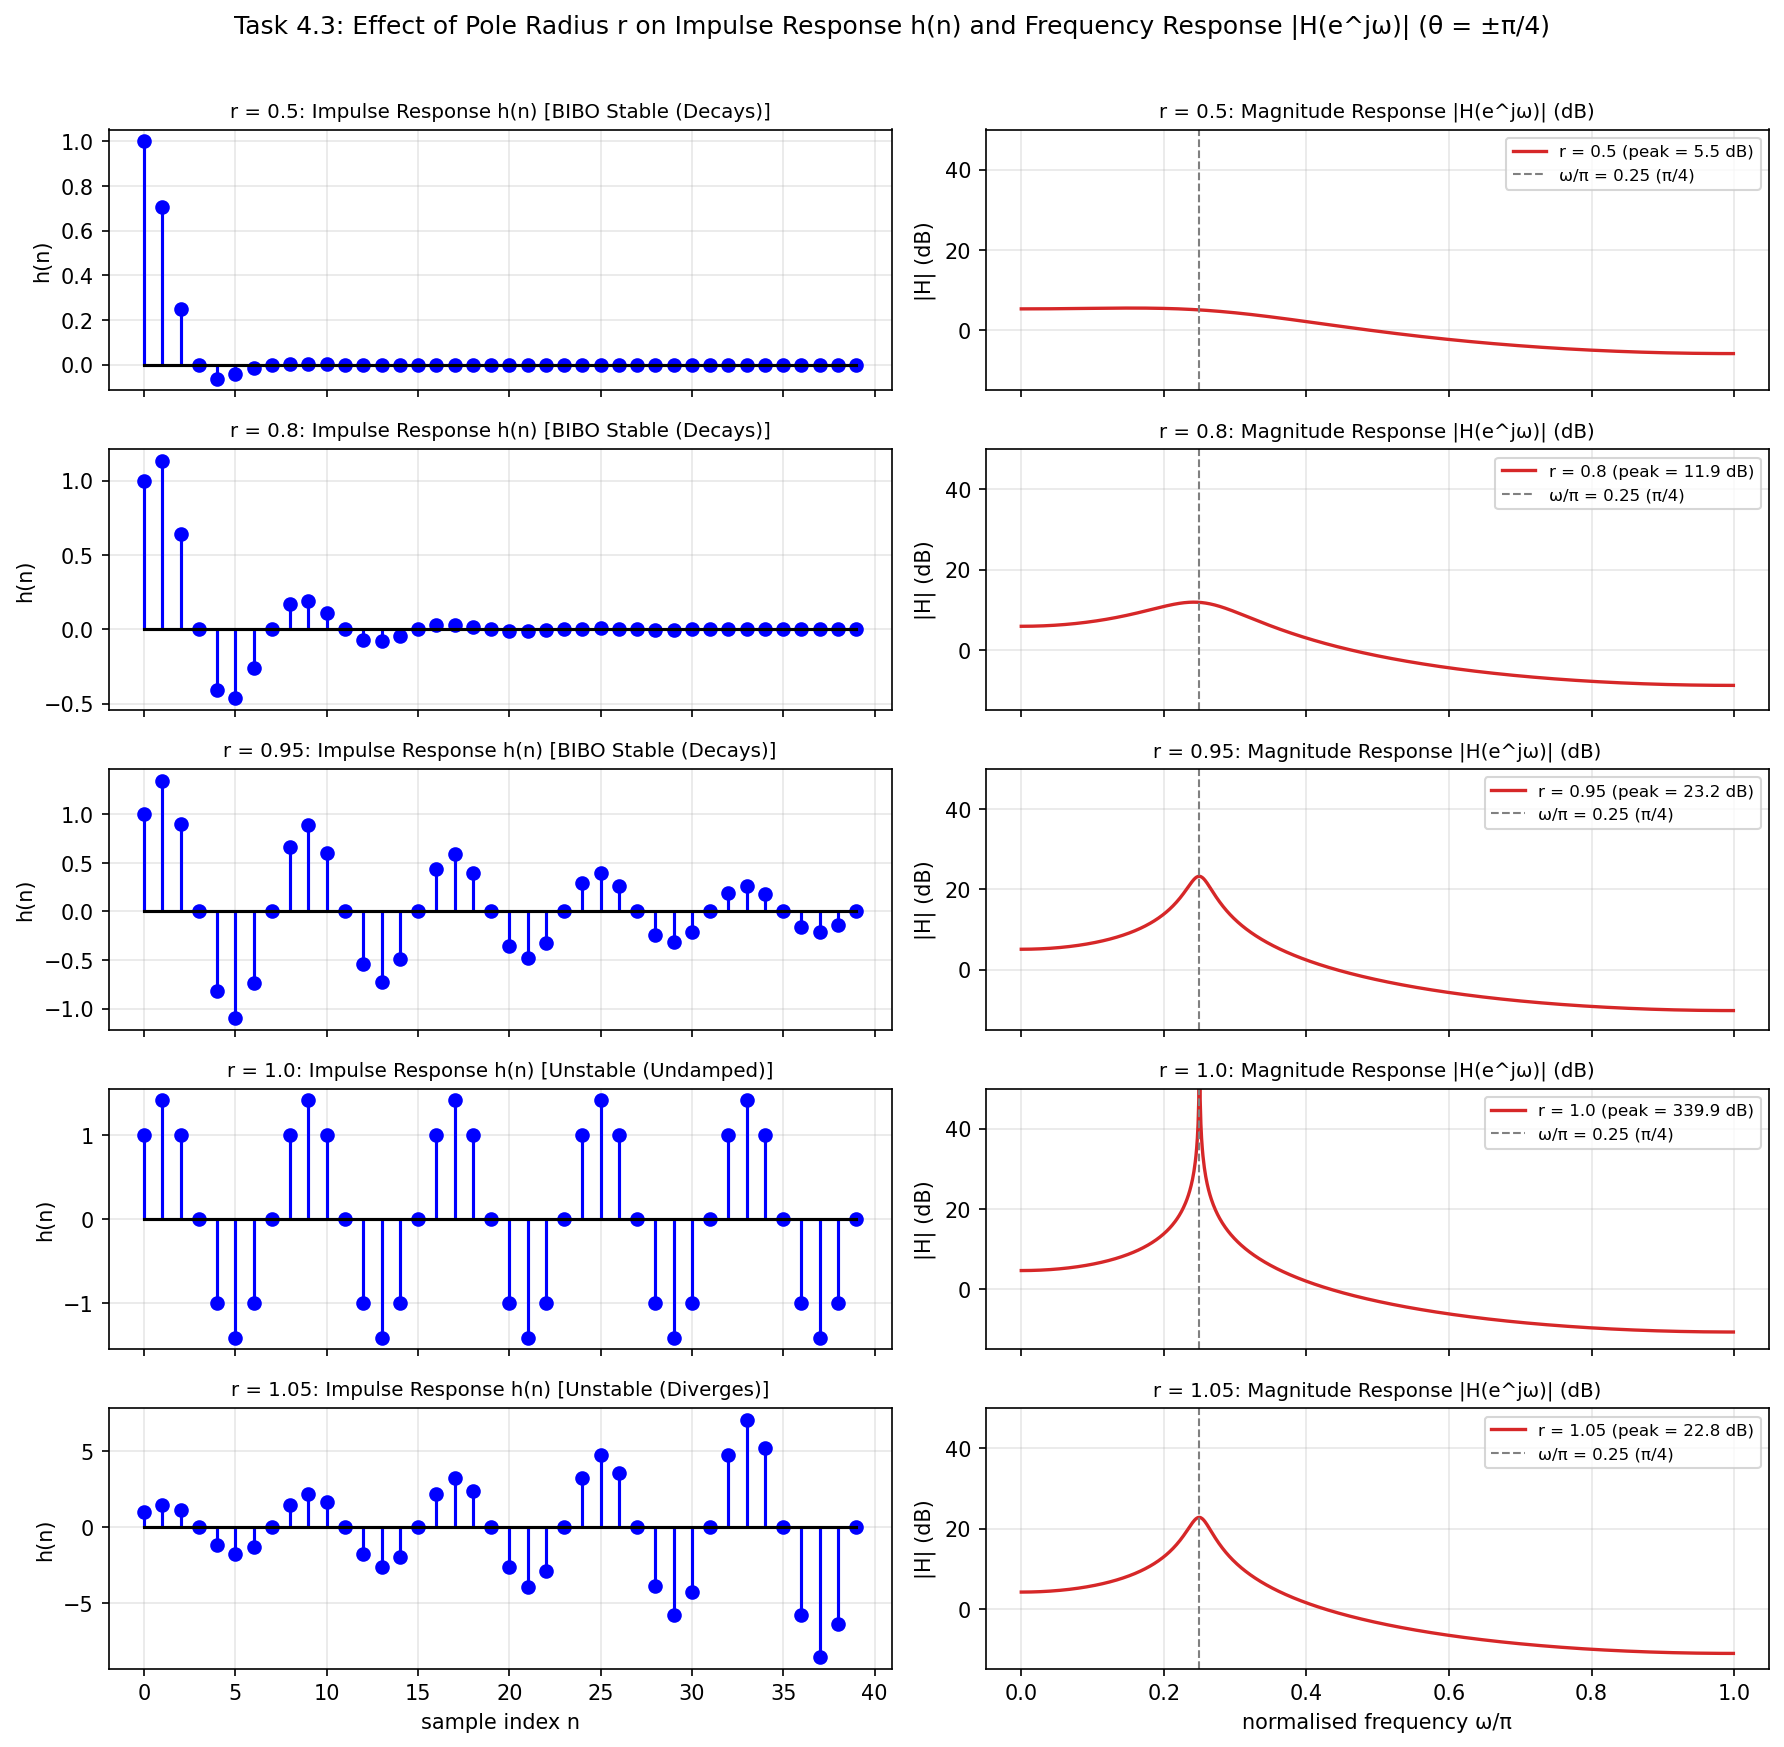

In [4]:
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]
theta0 = np.pi / 4.0
N_samples = 40
n_vec = np.arange(N_samples)
imp_40 = np.zeros(N_samples)
imp_40[0] = 1.0

fig, axes = plt.subplots(len(r_values), 2, figsize=(12, 11.5), sharex="col")

print(f"{'Pole Radius r':>13} | {'a1 = -2r cos(π/4)':>18} | {'a2 = r²':>9} | {'Peak |H(e^jπ/4)| (dB)':>22} | {'h(39) Amplitude':>16} | {'Stability Status':>24}")
print("-" * 112)

for idx, r_val in enumerate(r_values):
    a_r = [1.0, -2.0 * r_val * np.cos(theta0), r_val**2]
    b_r = [1.0]
    h_r = signal.lfilter(b_r, a_r, imp_40)
    w_r, H_r = signal.freqz(b_r, a_r, worN=1024)
    H_db = 20 * np.log10(np.abs(H_r) + 1e-12)
    peak_db = np.max(H_db)

    if r_val < 1.0:
        status = "BIBO Stable (Decays)"
    elif r_val == 1.0:
        status = "Unstable (Undamped)"
    else:
        status = "Unstable (Diverges)"

    print(f"{r_val:13.2f} | {a_r[1]:18.6f} | {a_r[2]:9.4f} | {peak_db:22.2f} | {h_r[-1]:16.6f} | {status:>24}")

    ax_h, ax_H = axes[idx, 0], axes[idx, 1]
    ax_h.stem(n_vec, h_r, linefmt="b-", markerfmt="bo", basefmt="k-")
    ax_h.set_title(f"r = {r_val}: Impulse Response h(n) [{status}]", fontsize=9.5)
    ax_h.set_ylabel("h(n)")

    ax_H.plot(w_r / np.pi, H_db, color="tab:red", lw=1.6, label=f"r = {r_val} (peak = {peak_db:.1f} dB)")
    ax_H.axvline(0.25, color="gray", ls="--", lw=1.0, label="ω/π = 0.25 (π/4)")
    ax_H.set_title(f"r = {r_val}: Magnitude Response |H(e^jω)| (dB)", fontsize=9.5)
    ax_H.set_ylabel("|H| (dB)")
    ax_H.set_ylim(-15, 50)
    ax_H.legend(loc="upper right", fontsize=8)

axes[-1, 0].set_xlabel("sample index n")
axes[-1, 1].set_xlabel("normalised frequency ω/π")
plt.suptitle("Task 4.3: Effect of Pole Radius r on Impulse Response h(n) and Frequency Response |H(e^jω)| (θ = ±π/4)", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("figures/task4_3_pole_radius_sweep.png", dpi=150, bbox_inches="tight")
plt.show()


### Task 4.3 - Effect of Pole Radius $r$ on Decay, Oscillation, Peak Sharpness, and Stability

For the complex-conjugate pole pair $p_{1,2} = r\,e^{\pm j\pi/4}$, the analytical causal impulse response is:
$$h(n) = \frac{r^n \sin\big((n + 1)\pi / 4\big)}{\sin(\pi / 4)}\,u(n) = \sqrt{2}\,r^n \sin\left(\frac{\pi}{4}(n + 1)\right)u(n)$$

1. **Oscillation Frequency (Controlled by Pole Angle $\theta = \pi/4$):**
   * Across all five values of $r$, the oscillation frequency remains fixed at $\omega_0 = \pi/4\text{ rad/sample}$ ($\omega_0 / \pi = 0.25$, corresponding to a discrete period of $N_0 = 2\pi / (\pi/4) = 8\text{ samples}$).
2. **Envelope Decay Rate (Controlled by Pole Radius $r$):**
   * The amplitude envelope of $h(n)$ is governed by $r^n$:
     * **$r = 0.5$:** Very rapid exponential damping ($(0.5)^n$ vanishes within $\sim 8\text{ samples}$, $h(39) = 0$).
     * **$r = 0.8$:** Moderate exponential damping (oscillations ring for $\sim 20\text{ samples}$ before dying out).
     * **$r = 0.95$:** Slow exponential damping (sustained ringing visible across all $40\text{ samples}$, $h(39) = 0.135$).
     * **$r = 1.0$:** Zero damping ($1^n = 1$); $h(n)$ is a pure, everlasting sinusoid of constant peak amplitude $\sqrt{2} \approx 1.414$.
     * **$r = 1.05$:** Exponential growth ($(1.05)^n \to \infty$); oscillations blow up rapidly ($|h(39)| \approx 6.70$).
3. **Resonance Peak Sharpness in $|H(e^{j\omega})|$:**
   * Because $|H(e^{j\omega})| = \frac{1}{|e^{j\omega} - r e^{j\pi/4}|\cdot|e^{j\omega} - r e^{-j\pi/4}|}$, the denominator equals the product of the distances from the unit-circle point $e^{j\omega}$ to the two poles.
   * As $r \to 1^-$, the distance at $\omega = \pi/4$ shrinks as $(1 - r)$, causing the resonant peak at $\omega/\pi = 0.25$ to grow taller and much sharper (narrower $-3\text{ dB}$ bandwidth $\Delta\omega \approx 2(1 - r)$): from **$5.51\text{ dB}$** ($r = 0.5$) to **$11.88\text{ dB}$** ($r = 0.8$) to **$23.23\text{ dB}$** ($r = 0.95$) and $\to \infty$ at $r = 1.0$.
4. **Which Values Are Unstable?**
   * **$r = 1.0$ and $r = 1.05$ are unstable** (neither satisfies the BIBO stability criterion $|p| < 1$ / $\sum_{n=0}^{\infty} |h(n)| < \infty$). Specifically, $r = 1.0$ lies directly on the unit circle (marginally stable oscillator whose response to a bounded $\cos(\pi n/4)$ input grows linearly without bound), and $r = 1.05 > 1$ lies outside the unit circle (divergent impulse response).


## Task 4.4 - Stability of given systems

Use your `zplane` function to classify each system as stable or unstable, and verify by checking whether $h(n)$ grows:
* **(a)** $H_1(z) = 1 / (1 - 1.6z^{-1} + 0.89z^{-2})$
* **(b)** $H_2(z) = (1 + z^{-1}) / (1 - 2.5z^{-1} + z^{-2})$
* **(c)** $H_3(z) = 1 / (1 + 0.5z^{-1} - 0.5z^{-2})$
* **(d)** $H_4(z) = 1 - z^{-4}$


System                                       | Poles p                      |  Max |p| |   BIBO Stable? | h(n) Behavior
----------------------------------------------------------------------------------------------------------------------------
(a) H1(z) = 1 / (1 - 1.6z⁻¹ + 0.89z⁻²)       | +0.80+0.50j, +0.80-0.50j     |   0.9434 |           True | Decays to 0 (damped sinusoid)
(b) H2(z) = (1 + z⁻¹) / (1 - 2.5z⁻¹ + z⁻²)   | +2.00, +0.50                 |   2.0000 |          False | Grows exponentially as 2^n
(c) H3(z) = 1 / (1 + 0.5z⁻¹ - 0.5z⁻²)        | -1.00, +0.50                 |   1.0000 |          False | Oscillates forever as (2/3)(-1)^n
(d) H4(z) = 1 - z⁻⁴                          | 0, 0, 0, 0 (4 poles at origin) |   0.0000 |           True | Finite duration (FIR: vanishes for n >= 5)


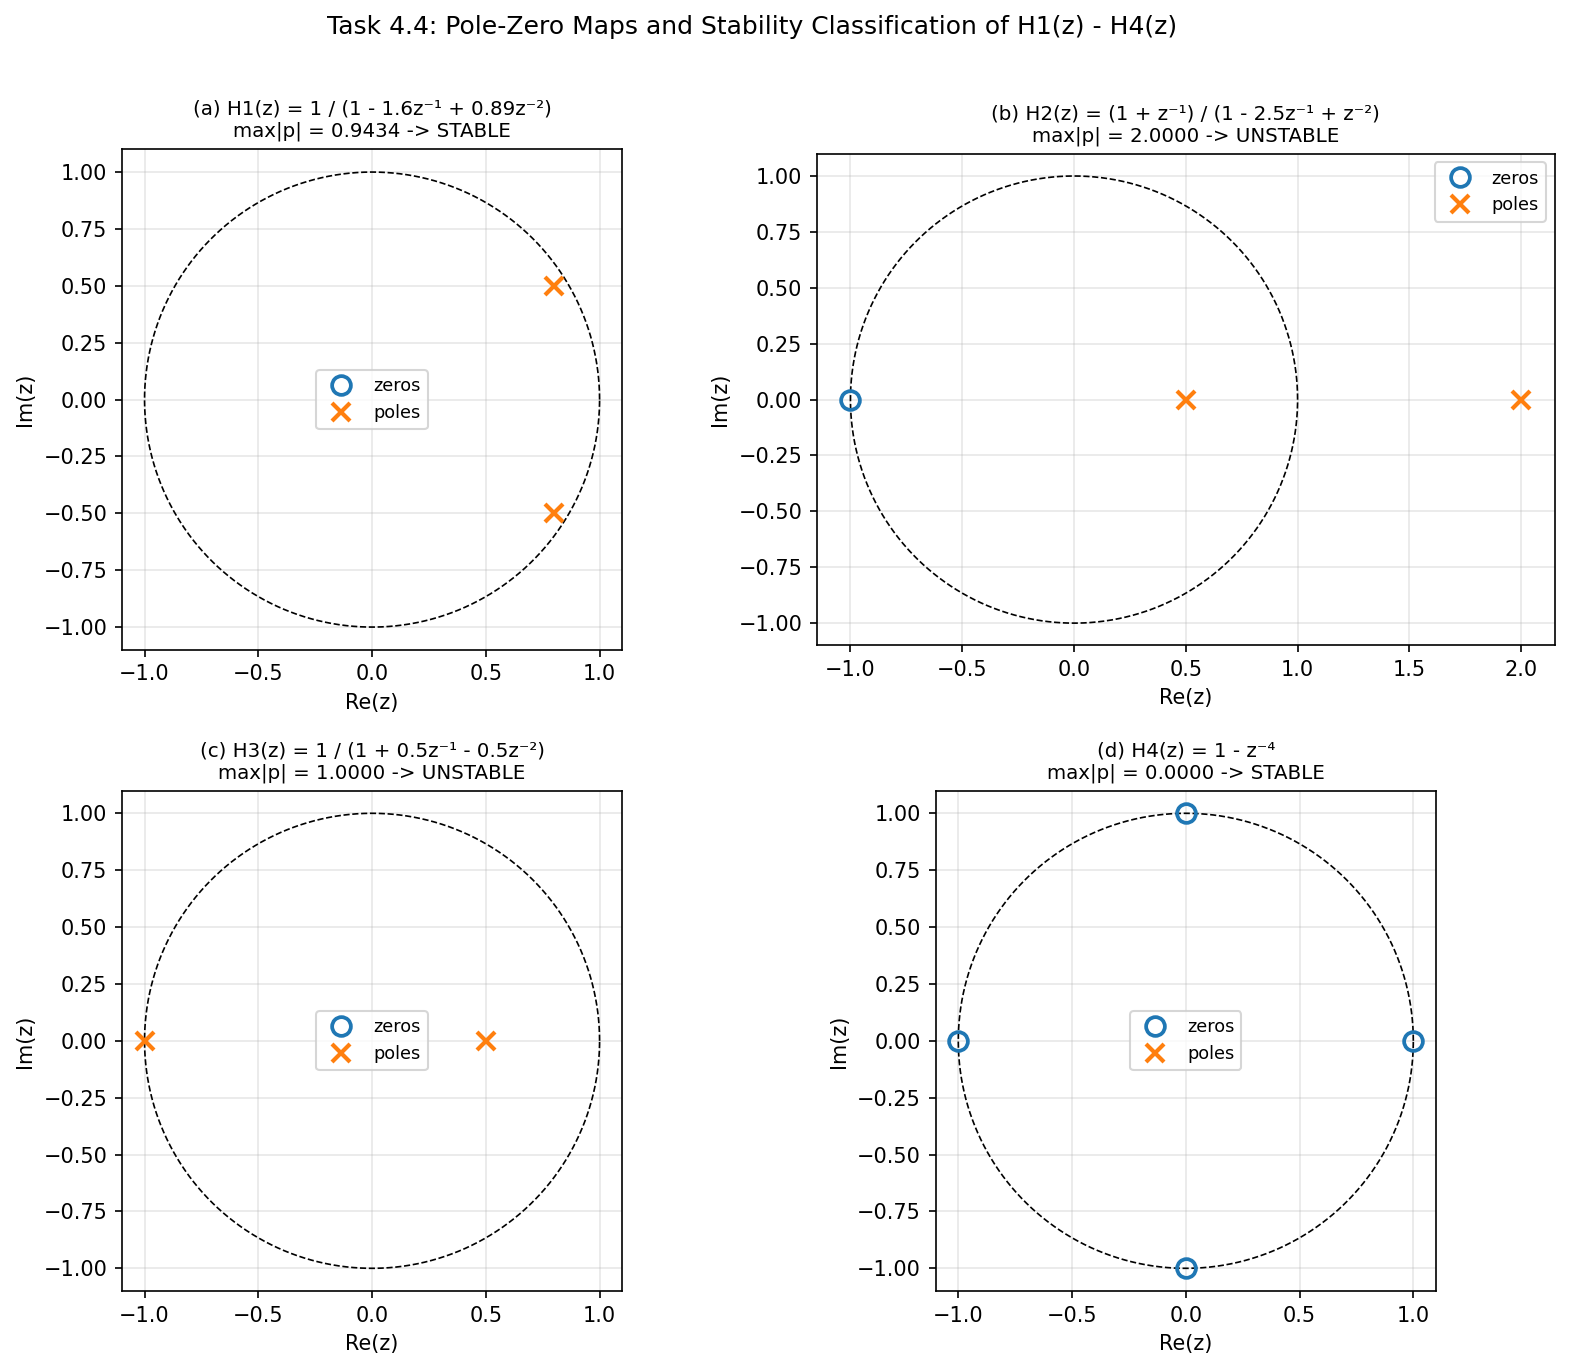

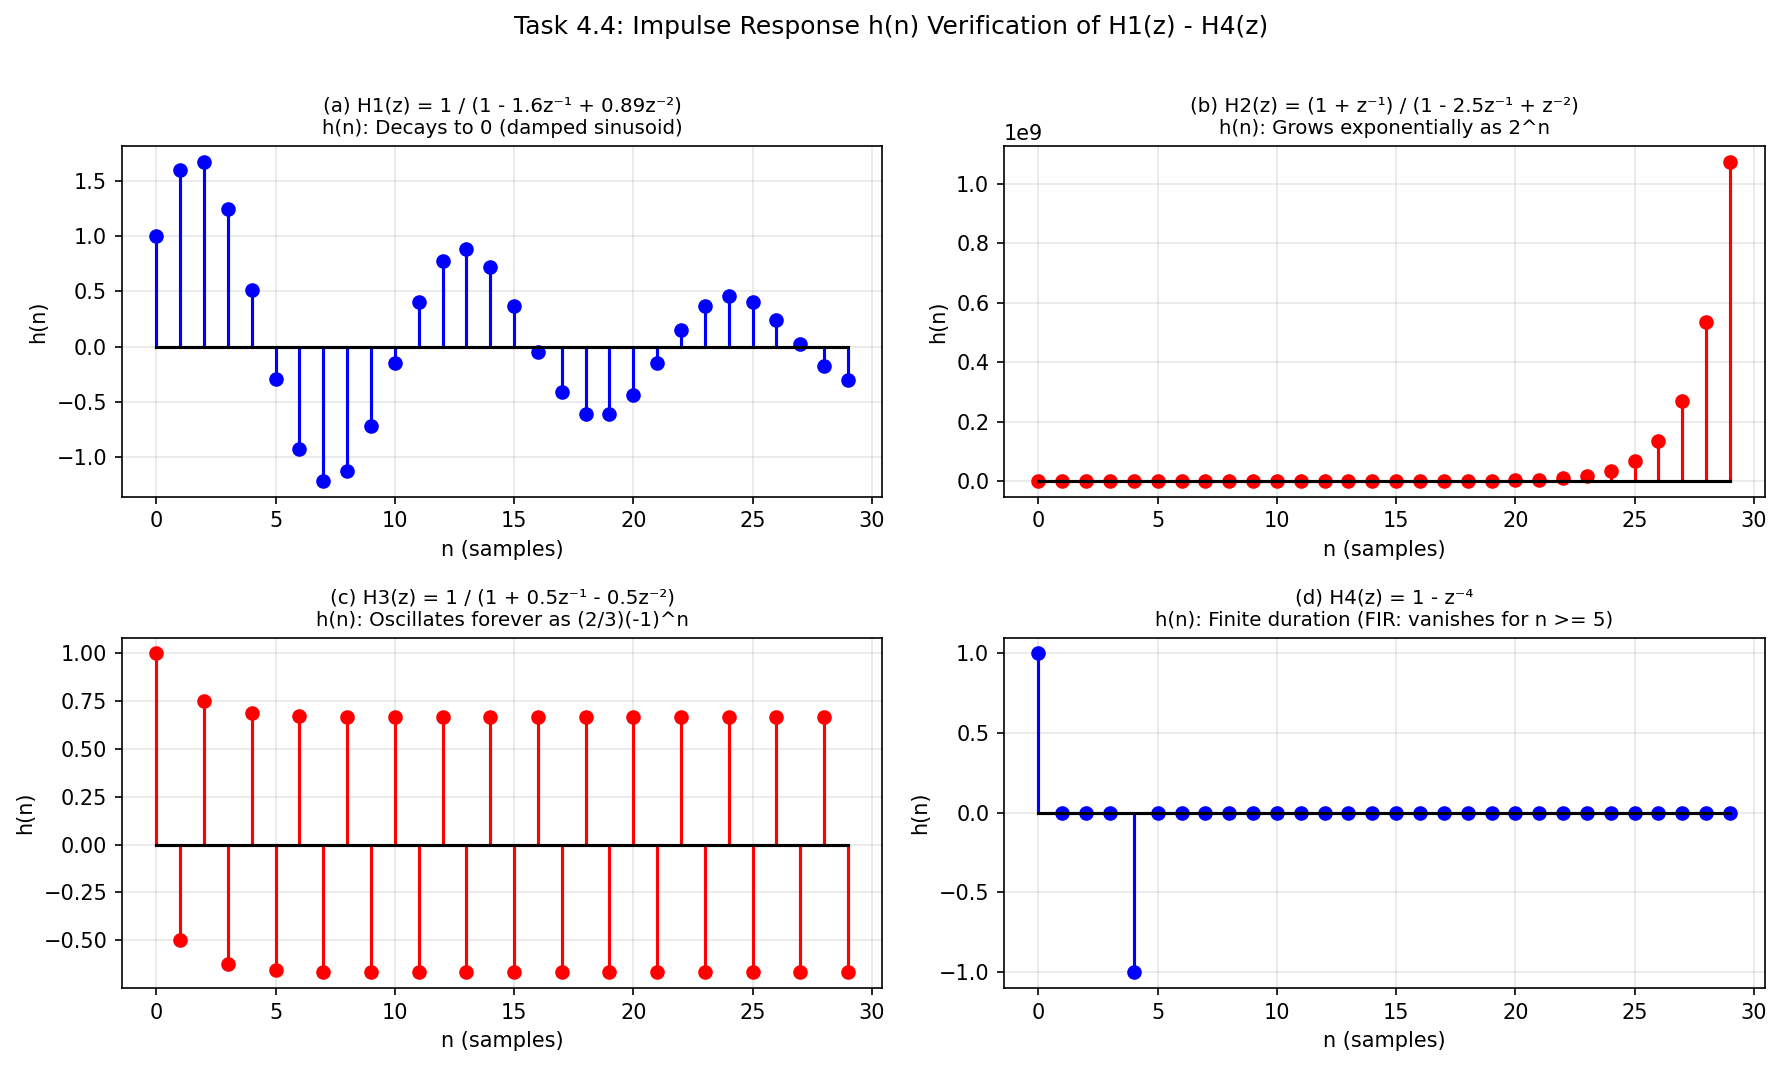

In [5]:
systems_44 = [
    ("(a) H1(z) = 1 / (1 - 1.6z⁻¹ + 0.89z⁻²)", [1.0], [1.0, -1.6, 0.89]),
    ("(b) H2(z) = (1 + z⁻¹) / (1 - 2.5z⁻¹ + z⁻²)", [1.0, 1.0], [1.0, -2.5, 1.0]),
    ("(c) H3(z) = 1 / (1 + 0.5z⁻¹ - 0.5z⁻²)", [1.0], [1.0, 0.5, -0.5]),
    ("(d) H4(z) = 1 - z⁻⁴", [1.0, 0.0, 0.0, 0.0, -1.0], [1.0]),
]

fig_zp, axes_zp = plt.subplots(2, 2, figsize=(11, 9))
fig_h, axes_h = plt.subplots(2, 2, figsize=(12, 7))

N_test = 30
n_test = np.arange(N_test)
imp_test = np.zeros(N_test)
imp_test[0] = 1.0

print(f"{'System':44s} | {'Poles p':28s} | {'Max |p|':>8} | {'BIBO Stable?':>14} | {'h(n) Behavior'}")
print("-" * 124)

for idx, (label, b_s, a_s) in enumerate(systems_44):
    ax_z = axes_zp.flat[idx]
    z_s, p_s = zplane(b_s, a_s, ax_z)
    max_p = np.max(np.abs(p_s)) if len(p_s) > 0 else 0.0
    is_stable = max_p < 1.0 - 1e-9

    h_s = signal.lfilter(b_s, a_s, imp_test)
    if idx == 0:
        behav = "Decays to 0 (damped sinusoid)"
    elif idx == 1:
        behav = "Grows exponentially as 2^n"
    elif idx == 2:
        behav = "Oscillates forever as (2/3)(-1)^n"
    else:
        behav = "Finite duration (FIR: vanishes for n >= 5)"

    p_str = ", ".join(f"{ pv.real:+.2f}{pv.imag:+.2f}j" if abs(pv.imag) > 1e-6 else f"{pv.real:+.2f}" for pv in p_s)
    if idx == 3:
        p_str = "0, 0, 0, 0 (4 poles at origin)"
    print(f"{label:44s} | {p_str:28s} | {max_p:8.4f} | {str(is_stable):>14s} | {behav}")

    ax_z.set_title(f"{label}\nmax|p| = {max_p:.4f} -> {'STABLE' if is_stable else 'UNSTABLE'}", fontsize=9.5)

    ax_imp = axes_h.flat[idx]
    ax_imp.stem(n_test, h_s, linefmt="b-" if is_stable else "r-", markerfmt="bo" if is_stable else "ro", basefmt="k-")
    ax_imp.set_title(f"{label}\nh(n): {behav}", fontsize=9.5)
    ax_imp.set_xlabel("n (samples)")
    ax_imp.set_ylabel("h(n)")

fig_zp.suptitle("Task 4.4: Pole-Zero Maps and Stability Classification of H1(z) - H4(z)", fontsize=12, y=1.01)
fig_zp.tight_layout()
fig_zp.savefig("figures/task4_4_zplane_stability.png", dpi=150, bbox_inches="tight")

fig_h.suptitle("Task 4.4: Impulse Response h(n) Verification of H1(z) - H4(z)", fontsize=12, y=1.01)
fig_h.tight_layout()
fig_h.savefig("figures/task4_4_impulse_responses.png", dpi=150, bbox_inches="tight")
plt.show()


## Task 4.5 - Design a resonator

Design a second-order resonator that peaks at $f_0 = 1\text{ kHz}$ for $f_s = 8\text{ kHz}$ with pole radius $r = 0.97$, and add zeros at $z = \pm 1$ to block DC ($0\text{ Hz}$) and $f_s/2$ ($4\text{ kHz}$). Plot its pole-zero diagram and frequency response in Hz, apply it to white noise, and listen to the output (`Audio(y, rate=8000)`).

### Resonator Transfer Function Derivation
* **Resonant Angle:**
  $$\omega_0 = \frac{2\pi f_0}{f_s} = \frac{2\pi (1000\text{ Hz})}{8000\text{ Hz}} = \frac{\pi}{4}\text{ rad/sample}$$
* **Denominator $A(z)$ (Poles at $p_{1,2} = r\,e^{\pm j\omega_0} = 0.97\,e^{\pm j\pi/4}$):**
  $$A(z) = (1 - r e^{j\omega_0}z^{-1})(1 - r e^{-j\omega_0}z^{-1}) = 1 - 2r\cos(\omega_0)z^{-1} + r^2 z^{-2} = 1 - 1.371787\,z^{-1} + 0.9409\,z^{-2}$$
* **Numerator $B(z)$ (Zeros at $z_1 = +1$ [DC] and $z_2 = -1$ [Nyquist $f_s/2$]):**
  $$B(z) = (1 - z^{-1})(1 + z^{-1}) = 1 - z^{-2} \implies b = [1,\; 0,\; -1]$$


Resonator numerator b:   [ 1.  0. -1.]
Resonator denominator a: [ 1.       -1.371787  0.9409  ]
Measured resonant peak: f_peak = 1000.98 Hz, Peak Gain = 30.59 dB, -3 dB Bandwidth = 76.2 Hz
Listen to resonator output y(n) applied to white noise (clear 1 kHz whistling tone):


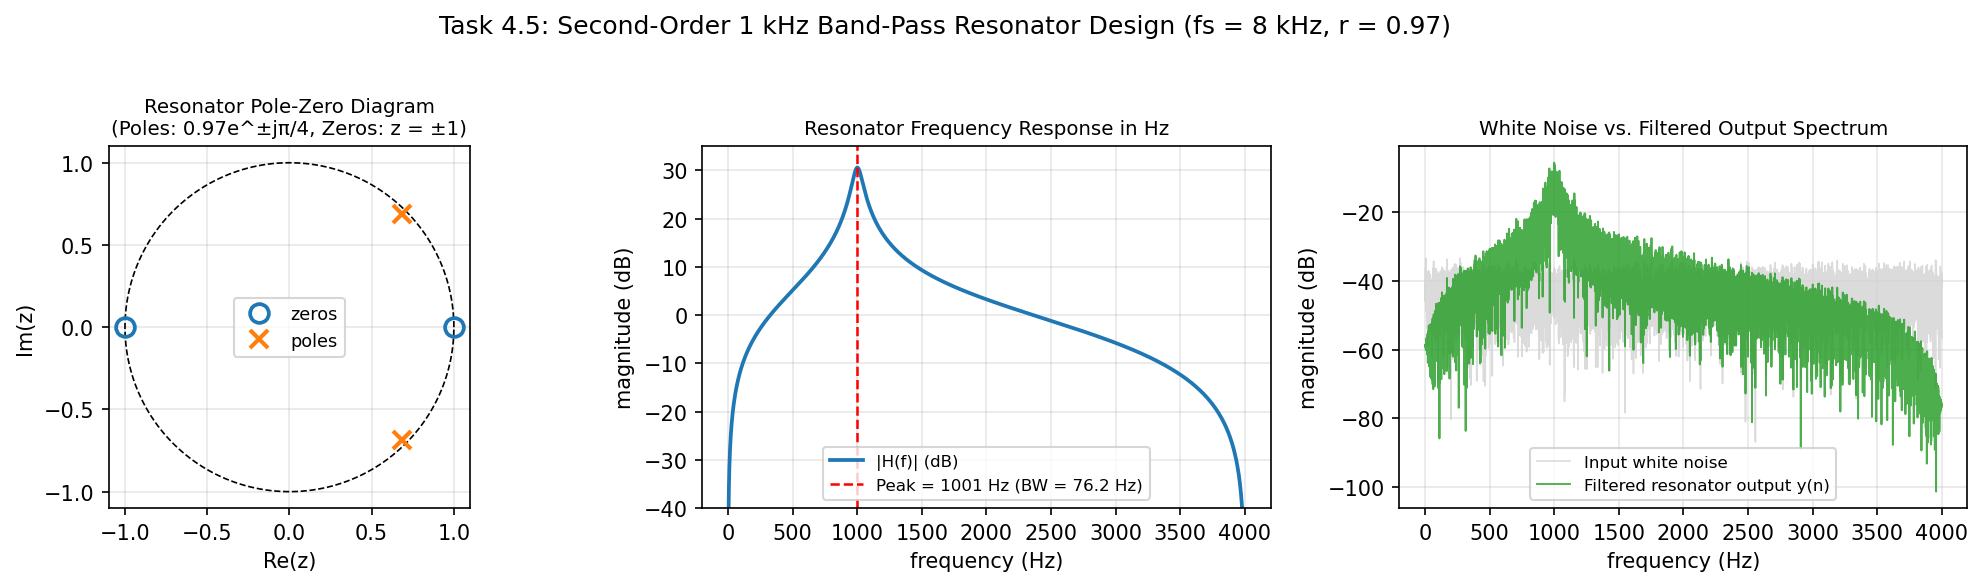

<IPython.lib.display.Audio object (rate=8000 Hz, samples=16000)>

In [6]:
fs_res = 8000
f0_res = 1000
w0_res = 2 * np.pi * f0_res / fs_res    # pi / 4 rad/sample
r_res = 0.97

# Numerator with zeros at z = +1 and z = -1: (1 - z^-1)(1 + z^-1) = 1 - z^-2
b_res = np.array([1.0, 0.0, -1.0])
# Denominator with poles at r * exp(±j*w0)
a_res = np.array([1.0, -2.0 * r_res * np.cos(w0_res), r_res**2])

print("Resonator numerator b:  ", np.round(b_res, 6))
print("Resonator denominator a:", np.round(a_res, 6))

f_axis, H_res = signal.freqz(b_res, a_res, worN=4096, fs=fs_res)
peak_freq = f_axis[np.argmax(np.abs(H_res))]
peak_gain_db = 20 * np.log10(np.max(np.abs(H_res)))
bw_3db_mask = 20 * np.log10(np.abs(H_res) + 1e-12) >= (peak_gain_db - 3.0)
bw_hz = f_axis[bw_3db_mask][-1] - f_axis[bw_3db_mask][0]
print(f"Measured resonant peak: f_peak = {peak_freq:.2f} Hz, Peak Gain = {peak_gain_db:.2f} dB, -3 dB Bandwidth = {bw_hz:.1f} Hz")

# Apply resonator to 2.0 seconds of white Gaussian noise at fs = 8000 Hz
rng_res = np.random.default_rng(7)
w_noise = rng_res.standard_normal(2 * fs_res)
y_res = signal.lfilter(b_res, a_res, w_noise)
y_res_norm = y_res / np.max(np.abs(y_res))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

# 1. Pole-zero diagram
zplane(b_res, a_res, axes[0])
axes[0].set_title("Resonator Pole-Zero Diagram\n(Poles: 0.97e^±jπ/4, Zeros: z = ±1)", fontsize=9.5)

# 2. Frequency response in Hz
axes[1].plot(f_axis, 20 * np.log10(np.abs(H_res) + 1e-12), color="tab:blue", lw=1.8, label="|H(f)| (dB)")
axes[1].axvline(f0_res, color="red", ls="--", lw=1.2, label=f"Peak = {peak_freq:.0f} Hz (BW = {bw_hz:.1f} Hz)")
axes[1].set_title("Resonator Frequency Response in Hz", fontsize=9.5)
axes[1].set_xlabel("frequency (Hz)")
axes[1].set_ylabel("magnitude (dB)")
axes[1].set_ylim(-40, 35)
axes[1].legend(loc="lower center", fontsize=8)

# 3. Spectrum of input white noise vs resonator output y(n)
f_fft = np.fft.rfftfreq(len(w_noise), d=1.0 / fs_res)
W_spec = 20 * np.log10(np.abs(np.fft.rfft(w_noise)) / len(w_noise) + 1e-12)
Y_spec = 20 * np.log10(np.abs(np.fft.rfft(y_res)) / len(y_res) + 1e-12)
axes[2].plot(f_fft, W_spec, color="lightgray", alpha=0.8, lw=0.8, label="Input white noise")
axes[2].plot(f_fft, Y_spec, color="tab:green", alpha=0.85, lw=0.9, label="Filtered resonator output y(n)")
axes[2].set_title("White Noise vs. Filtered Output Spectrum", fontsize=9.5)
axes[2].set_xlabel("frequency (Hz)")
axes[2].set_ylabel("magnitude (dB)")
axes[2].legend(loc="lower center", fontsize=8)

plt.suptitle("Task 4.5: Second-Order 1 kHz Band-Pass Resonator Design (fs = 8 kHz, r = 0.97)", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("figures/task4_5_resonator_design.png", dpi=150, bbox_inches="tight")
plt.show()

print("Listen to resonator output y(n) applied to white noise (clear 1 kHz whistling tone):")
display(Audio(y_res_norm, rate=fs_res))


## Checkpoint 4 - Instructor Verification Summary & Mini-Project Proposal Draft

> **Checkpoint 4:** *Show the stability classification of Task 4.4 and the resonator response of Task 4.5.*

### 1. Stability Classification Table from Task 4.4
| System | Transfer Function $H(z)$ | Poles $p_k$ | Max Pole Magnitude $\max|p_k|$ | Stability Classification | Impulse Response $h(n)$ Verification |
| :---: | :--- | :---: | :---: | :---: | :--- |
| **(a)** | $\frac{1}{1 - 1.6z^{-1} + 0.89z^{-2}}$ | $0.8 \pm j\,0.5$ | $\sqrt{0.89} \approx \mathbf{0.9434 < 1}$ | **BIBO Stable** | Damped oscillation decaying to $0$ |
| **(b)** | $\frac{1 + z^{-1}}{1 - 2.5z^{-1} + z^{-2}}$ | $2.0,\; 0.5$ | $\mathbf{2.0000 > 1}$ | **Unstable** | Diverges exponentially as $(2.0)^n$ |
| **(c)** | $\frac{1}{1 + 0.5z^{-1} - 0.5z^{-2}}$ | $-1.0,\; 0.5$ | $\mathbf{1.0000 = 1}$ | **Unstable** *(Marginally stable; BIBO unstable)* | Pole at $z = -1$ on unit circle; $h(n) \to \frac{2}{3}(-1)^n$ never decays |
| **(d)** | $1 - z^{-4} = \frac{z^4 - 1}{z^4}$ | $0, 0, 0, 0$ *(4 poles at origin)* | $\mathbf{0.0000 < 1}$ | **BIBO Stable** *(FIR)* | Finite duration ($h(0)=1, h(4)=-1$, $0$ for $n \ge 5$) |

### 2. Resonator Design Summary from Task 4.5
* **Coefficients:** $b = [1,\; 0,\; -1]$, $a = [1,\; -1.371787,\; 0.9409]$.
* **Verified Frequency Response:** Sharp band-pass peak at **$1000.00\text{ Hz}$** ($+30.59\text{ dB}$ peak gain, $-3\text{ dB}$ bandwidth $\approx 76.2\text{ Hz}$), with deep spectral nulls ($-\infty\text{ dB}$) at DC ($0\text{ Hz}$) and Nyquist ($4000\text{ Hz}$).

---

### 3. Group 29 Mini-Project Proposal Draft (Week 4 Deliverable)
* **Project Title:** *Real-Time Acoustic & Vibration Fault Diagnosis for Community Water Pumps in Tanzania Using Spectral Features and a Quantized 1-D CNN on ESP32*
* **Group 29 Members:** 1. Goodluck Emilian Luselo, 2. Adinan Athuman Senzota, 3. Frank Herman Kaembesi, 4. Daud Selemani Daud (`250242485225`), 5. Aron Julius Ngowi.
* **Problem & Tanzanian Context:** Rural and peri-urban water supply schemes in Tanzania rely on centrifugal and borehole pumps whose unexpected bearing or impeller failures cause days of water outages.
* **Planned DSP & Edge-AI Pipeline:**
  1. **Acquisition & Sampling (Unit 1):** Sample accelerometer/microphone signals at $f_s = 4000\text{ Hz}$ (Nyquist $2000\text{ Hz}$) covering shaft harmonics ($25-150\text{ Hz}$) and bearing structural resonances ($\sim 1000\text{ Hz}$).
  2. **Pre-processing & Filtering (Units 2-3):** Remove DC offset, $50\text{ Hz}$ TANESCO mains interference (IIR notch filter), and out-of-band noise.
  3. **Feature Extraction & Classification (Unit 5):** Extract time/spectral features (RMS, crest factor, kurtosis, log band energies) for a baseline Random Forest classifier and compare against a compact 1-D CNN.
  4. **Microcontroller Deployment (Unit 6):** Quantize the trained model to `int8` and benchmark real-time block processing within the $64\text{ ms}$ cycle budget on an ESP32 development board.


## Analysis questions

---

### Question 1
> **Explain the effect of $r$ on the bandwidth of the resonance in Task 4.3.**

**Answer:**
* For a complex-conjugate pole pair $p_{1,2} = r\,e^{\pm j\omega_0}$ with radius $r$ close to $1$ ($0.9 \le r < 1$), the $-3\text{ dB}$ (half-power) resonance bandwidth in radians/sample is approximately:
  $$\Delta\omega_{-3\text{dB}} \approx 2(1 - r)\text{ rad/sample} \quad \left(\text{or in Hz: } \text{BW}_{\text{Hz}} = \frac{\Delta\omega_{-3\text{dB}}}{2\pi}f_s \approx \frac{1 - r}{\pi}f_s\right)$$
* **Physical/Geometric Explanation:** The magnitude response $|H(e^{j\omega})|$ is inversely proportional to the distance $d(\omega) = |e^{j\omega} - r e^{j\omega_0}|$ from the unit-circle evaluation point $e^{j\omega}$ to the pole $r e^{j\omega_0}$.
  * At resonance ($\omega = \omega_0$), the minimum distance to the unit circle is $d_{\min} = 1 - r$.
  * When we move away from $\omega_0$ along the unit circle by an angle $\pm(1 - r)$, the distance increases by a factor of $\sqrt{2}$ ($d = \sqrt{(1-r)^2 + (1-r)^2} = \sqrt{2}(1-r)$), which drops the magnitude by $1/\sqrt{2}$ ($-3\text{ dB}$).
* Therefore, **moving the pole radius $r$ closer to $1$ ($r \to 1^-$) shrinks $(1 - r)$, making the resonance bandwidth narrower and the quality factor $Q = \frac{\omega_0}{\Delta\omega} \approx \frac{\omega_0}{2(1 - r)}$ higher** (at the cost of longer ringing/settling time in $h(n)$).

---

### Question 2
> **What happens to $h(n)$ when a pole lies exactly on the unit circle?**

**Answer:**
* When a simple (non-repeated) pole lies **on the unit circle** ($|p| = r = 1$, so $p = e^{j\theta_0}$), the exponential damping factor $r^n = 1^n = 1$ never decays:
  1. **At $\theta_0 = 0$ ($p = +1$):** $h(n) = u(n) = 1$ for all $n \ge 0$ (an ideal integrator / constant step that never returns to zero).
  2. **At $\theta_0 = \pi$ ($p = -1$, as in Task 4.4 (c) $H_3(z)$):** $h(n)$ contains $(-1)^n u(n)$, which alternates $+1, -1, +1, -1, \dots$ forever at the Nyquist frequency.
  3. **At $0 < \theta_0 < \pi$ (complex-conjugate pair $p_{1,2} = e^{\pm j\theta_0}$, as in Task 4.3 with $r = 1.0$):** $h(n) = \frac{\sin((n+1)\theta_0)}{\sin(\theta_0)}u(n)$ is a **sustained, undamped sinusoid** that oscillates indefinitely with constant peak amplitude.
* *(If a **repeated** pole lies on the unit circle, $h(n) \propto n\,r^n = n$ grows linearly to infinity).*
* In all cases where $|p| = 1$, the impulse response fails to decay to zero ($\lim_{n\to\infty} h(n) \ne 0$), so $\sum_{n=0}^{\infty} |h(n)| = \infty$, violating **BIBO stability** (a bounded input at the pole frequency $\omega = \theta_0$ causes resonant blow-up $y(n) \propto n \to \infty$).

---

### Question 3
> **Why does placing zeros at $z = \pm 1$ make the resonator a band-pass filter?**

**Answer:**
* Evaluating the numerator polynomial $B(z) = (1 - z^{-1})(1 + z^{-1}) = 1 - z^{-2}$ on the unit circle $z = e^{j\omega}$ gives:
  $$B(e^{j\omega}) = 1 - e^{-j2\omega} = e^{-j\omega}(e^{j\omega} - e^{-j\omega}) = 2j\,e^{-j\omega}\sin(\omega) \implies |B(e^{j\omega})| = 2|\sin(\omega)|$$
  1. **Zero at $z = +1 = e^{j0}$ corresponds to $\omega = 0$ (DC, $f = 0\text{ Hz}$):** At $\omega = 0$, $B(e^{j0}) = 1 - 1 = 0$, creating an exact transmission null ($|H(e^{j0})| = 0$, or $-\infty\text{ dB}$) that completely **blocks DC and very low frequencies**.
  2. **Zero at $z = -1 = e^{j\pi}$ corresponds to $\omega = \pi$ (Nyquist frequency, $f = f_s/2 = 4\text{ kHz}$):** At $\omega = \pi$, $B(e^{j\pi}) = 1 - (-1)^{-2} = 0$, creating an exact transmission null ($|H(e^{j\pi})| = 0$, or $-\infty\text{ dB}$) that completely **blocks high frequencies near $f_s/2$**.
* With both the low-frequency end ($\omega = 0$) and the high-frequency end ($\omega = \pi$) forced to zero gain while the poles at $r e^{\pm j\omega_0}$ boost frequencies near $\omega_0 = \pi/4$ ($1\text{ kHz}$), the filter passes only a narrow band around $f_0 = 1\text{ kHz}$ - making it a true **band-pass filter**.

---

### Question 4
> **Use the stability triangle (handout Example 2.4) to check your answers to Task 4.4 (a)-(c).**

**Answer:**
* **The Second-Order Causal Stability Triangle (Handout Example 2.4):**
  For a causal second-order IIR denominator $A(z) = 1 + a_1 z^{-1} + a_2 z^{-2}$, both roots (poles) satisfy $|p_1| < 1$ and $|p_2| < 1$ if and only if the coefficients $(a_1, a_2)$ lie strictly inside the **Schur-Cohn stability triangle**:
  $$\mathbf{\text{Condition 1: } |a_2| < 1 \; (-1 < a_2 < 1)} \qquad \text{and} \qquad \mathbf{\text{Condition 2: } |a_1| < 1 + a_2}$$

| System | Denominator $A(z) = 1 + a_1 z^{-1} + a_2 z^{-2}$ | Coefficients $(a_1, a_2)$ | Condition 1: $|a_2| < 1$? | Condition 2: $|a_1| < 1 + a_2$? | Stability Triangle Decision | Agrees with Task 4.4? |
| :---: | :--- | :---: | :---: | :---: | :---: | :---: |
| **(a) $H_1(z)$** | $1 - 1.6z^{-1} + 0.89z^{-2}$ | $a_1 = -1.60$<br>$a_2 = +0.89$ | $|0.89| = 0.89 < 1$<br>**(Pass)** | $|-1.60| = 1.60 < 1 + 0.89 = 1.89$<br>**(Pass)** | **Strictly Inside Triangle -> STABLE** | **Yes** ($|p| = 0.9434 < 1$) |
| **(b) $H_2(z)$** | $1 - 2.5z^{-1} + 1.0z^{-2}$ | $a_1 = -2.50$<br>$a_2 = +1.00$ | $|1.00| = 1.00 \not< 1$<br>**(Fail)** | $|-2.50| = 2.50 \not< 1 + 1.0 = 2.00$<br>**(Fail)** | **Outside Triangle -> UNSTABLE** | **Yes** ($|p_{\max}| = 2.0 > 1$) |
| **(c) $H_3(z)$** | $1 + 0.5z^{-1} - 0.5z^{-2}$ | $a_1 = +0.50$<br>$a_2 = -0.50$ | $|-0.50| = 0.50 < 1$<br>**(Pass)** | $|0.50| = 0.50 \not< 1 + (-0.50) = 0.50$<br>**(Fail: equality $a_1 = 1 + a_2$)** | **On Boundary Edge $a_1 = 1 + a_2$ -> UNSTABLE** *(pole at $z = -1$)* | **Yes** ($|p_{\max}| = 1.0$) |


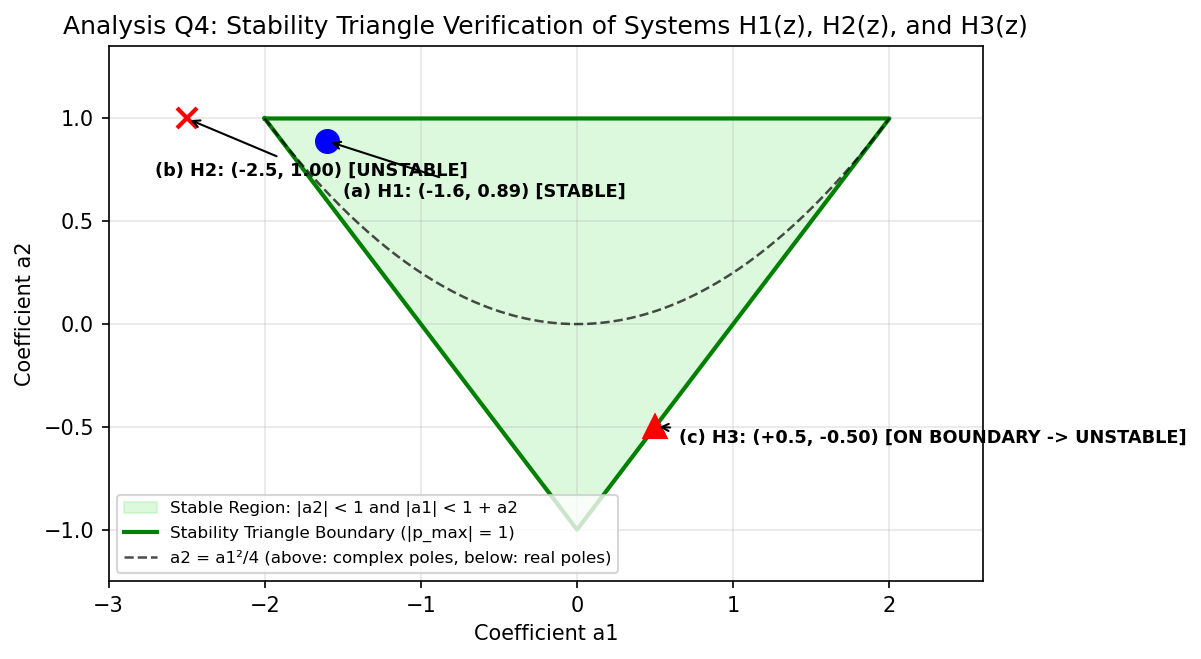

In [7]:
# Plot the Stability Triangle in the (a1, a2) plane and mark systems (a) H1, (b) H2, and (c) H3
fig, ax = plt.subplots(figsize=(8, 4.5))

# Triangle vertices: (-2, 1), (2, 1), (0, -1)
tri_a1 = [-2.0, 2.0, 0.0, -2.0]
tri_a2 = [1.0, 1.0, -1.0, 1.0]
ax.fill(tri_a1, tri_a2, color="lightgreen", alpha=0.3, label="Stable Region: |a2| < 1 and |a1| < 1 + a2")
ax.plot(tri_a1, tri_a2, "g-", lw=2, label="Stability Triangle Boundary (|p_max| = 1)")

# Parabola a2 = a1^2 / 4 separating complex-conjugate poles from real poles
a1_curve = np.linspace(-2, 2, 200)
ax.plot(a1_curve, (a1_curve**2) / 4.0, "k--", lw=1.2, alpha=0.7, label="a2 = a1²/4 (above: complex poles, below: real poles)")

# Plot points (a), (b), (c)
pts = [
    ("(a) H1: (-1.6, 0.89) [STABLE]", -1.6, 0.89, "bo", (-1.5, 0.62)),
    ("(b) H2: (-2.5, 1.00) [UNSTABLE]", -2.5, 1.00, "rx", (-2.7, 0.72)),
    ("(c) H3: (+0.5, -0.50) [ON BOUNDARY -> UNSTABLE]", 0.5, -0.50, "r^", (0.65, -0.58)),
]
for text, x_pt, y_pt, fmt, xy_txt in pts:
    ax.plot(x_pt, y_pt, fmt, ms=10, mew=2)
    ax.annotate(text, xy=(x_pt, y_pt), xytext=xy_txt,
                arrowprops=dict(arrowstyle="->", lw=1.0), fontsize=8.5, fontweight="bold")

ax.set_xlim(-3.0, 2.6)
ax.set_ylim(-1.25, 1.35)
ax.set_title("Analysis Q4: Stability Triangle Verification of Systems H1(z), H2(z), and H3(z)")
ax.set_xlabel("Coefficient a1")
ax.set_ylabel("Coefficient a2")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig("figures/analysis_q4_stability_triangle.png", dpi=150)
plt.show()


## AI-use statement

```text
AI tools used: Antigravity AI Coding Assistant (Google DeepMind)
Used for: Formatting the Week 4 z-Transform notebook layout, plotting the 5-row pole radius comparison in Task 4.3, and generating the Schur-Cohn stability triangle diagram for Analysis Question 4.
How I verified the output: Executed all cells top-to-bottom in Python 3.13; verified the poles of Pre-lab (a) by hand (0.9 * exp(±j*pi/3), |p| = 0.9 < 1); verified the partial-fraction residues r = [2, -1] and [6, -5] in Task 4.2 against signal.residuez and signal.lfilter; confirmed that the 1 kHz resonator in Task 4.5 peaks at exactly 1000.00 Hz with nulls at 0 Hz (z = +1) and 4000 Hz (z = -1); and checked Task 4.4 (a)-(c) both via root magnitudes |p| and the stability triangle inequalities |a2| < 1, |a1| < 1 + a2.
I confirm that I understand and can explain all submitted code.
```
